<a href="https://colab.research.google.com/github/bandapraneeth/Quantum-Hackathon/blob/main/question_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas scikit-learn

In [2]:
import pandas as pd
from sklearn.datasets import load_iris
from google.colab import files

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

# Select two classes for binary classification
df = df[df['target'].isin([0, 1])]

df.to_csv('iris.csv', index=False)

files.download('iris.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd
from sklearn.datasets import make_moons
from google.colab import files

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
df['target'] = y

df.to_csv('two_moons.csv', index=False)

files.download('two_moons.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
!pip install pennylane scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 38.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 66.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 68.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 62.6 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [5]:
import pennylane as qml
from pennylane import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
iris = load_iris()

X_iris = iris.data[iris.target < 2][:, :2]
y_iris = iris.target[iris.target < 2]

print("Iris Dataset")
print("Features:", X_iris.shape)
print("Labels:", y_iris.shape)
print("Classes:", np.unique(y_iris))

Iris Dataset
Features: (100, 2)
Labels: (100,)
Classes: [0 1]


In [7]:
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.2,
    random_state=42
)

print("Two Moons Dataset")
print("Features:", X_moons.shape)
print("Labels:", y_moons.shape)
print("Classes:", np.unique(y_moons))

Two Moons Dataset
Features: (300, 2)
Labels: (300,)
Classes: [0 1]


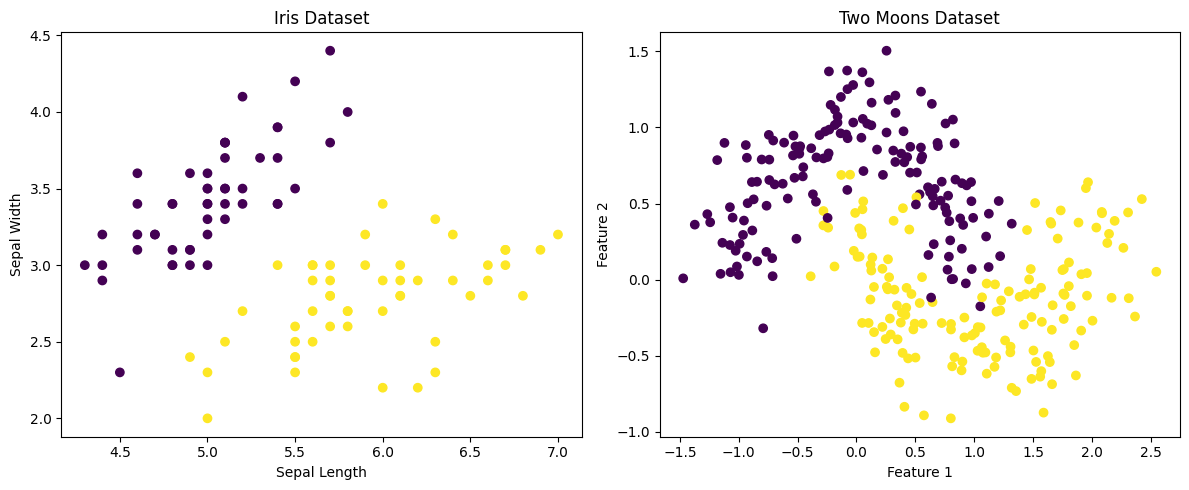

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=y_iris)
plt.title("Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.subplot(1, 2, 2)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons)
plt.title("Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [9]:
def preprocess(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return X_train, X_test, y_train, y_test


iris_data = preprocess(X_iris, y_iris)
moons_data = preprocess(X_moons, y_moons)

print("Both datasets preprocessed successfully!")

Both datasets preprocessed successfully!


In [10]:
n_qubits = 2
n_layers = 2

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="autograd")
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(n_qubits),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(n_qubits)
    )

    return qml.expval(qml.PauliZ(0))


weight_shape = qml.StronglyEntanglingLayers.shape(
    n_layers=n_layers,
    n_wires=n_qubits
)

weights = np.random.normal(
    0,
    0.1,
    size=weight_shape,
    requires_grad=True
)

print("Quantum circuit initialized!")
print("Number of Qubits:", n_qubits)
print("Number of Layers:", n_layers)
print(qml.draw(quantum_circuit)(np.array([0.5, 0.8]), weights))

Quantum circuit initialized!
Number of Qubits: 2
Number of Layers: 2
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     

M0 = 
[0.5 0.8]
M1 = 
[[[-0.08603248  0.03939652 -0.1624292 ]
  [ 0.1061073   0.11038587  0.017314  ]]

 [[-0.16588344 -0.0404642   0.01353979]
  [ 0.14704956 -0.01657366 -0.0117228 ]]]


In [14]:
def predict_probability(x, weights):
    output = quantum_circuit(x, weights)
    return (1 - output) / 2


def loss_function(weights, X, y):

    predictions = np.stack([
        predict_probability(x, weights)
        for x in X
    ])

    predictions = np.clip(predictions, 1e-7, 1 - 1e-7)

    loss = -np.mean(
        y * np.log(predictions) +
        (1 - y) * np.log(1 - predictions)
    )

    return loss

print("Loss function defined successfully!")

Loss function defined successfully!


In [15]:
def train_model(X_train, y_train, epochs=40):

    X_train = np.array(X_train, requires_grad=False)
    y_train = np.array(y_train, requires_grad=False)

    weights = np.random.normal(
        0, 0.1,
        size=weight_shape,
        requires_grad=True
    )

    optimizer = qml.AdamOptimizer(stepsize=0.03)

    losses = []

    start_time = time.time()

    for epoch in range(epochs):

        weights = optimizer.step(
            lambda w: loss_function(w, X_train, y_train),
            weights
        )

        current_loss = loss_function(
            weights, X_train, y_train
        )

        losses.append(float(current_loss))

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {current_loss:.4f}")

    training_time = time.time() - start_time

    return weights, losses, training_time

In [16]:
print("Training on Iris Dataset")

iris_weights, iris_losses, iris_time = train_model(
    X_train_i, y_train_i
)

print("\nTraining on Two Moons Dataset")

moons_weights, moons_losses, moons_time = train_model(
    X_train_m, y_train_m
)

Training on Iris Dataset
Epoch 10/40, Loss: 0.4750
Epoch 20/40, Loss: 0.3092
Epoch 30/40, Loss: 0.2714
Epoch 40/40, Loss: 0.2615

Training on Two Moons Dataset
Epoch 10/40, Loss: 0.6910
Epoch 20/40, Loss: 0.5506
Epoch 30/40, Loss: 0.4989
Epoch 40/40, Loss: 0.4798


In [17]:
eval_dev = qml.device(
    "default.qubit",
    wires=n_qubits,
    shots=1000
)

@qml.qnode(eval_dev)
def evaluation_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(n_qubits),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(n_qubits)
    )

    return qml.expval(qml.PauliZ(0))


def evaluate_model(X_test, y_test, weights):

    start = time.time()

    probabilities = np.array([
        (1 - evaluation_circuit(x, weights)) / 2
        for x in X_test
    ])

    inference_time = time.time() - start

    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, predictions)
    balanced = balanced_accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    auc = roc_auc_score(y_test, probabilities)

    cm = confusion_matrix(y_test, predictions)

    print("Accuracy:", accuracy)
    print("Balanced Accuracy:", balanced)
    print("Macro-F1:", macro_f1)
    print("AUROC:", auc)
    print("Confusion Matrix:\n", cm)
    print("Inference Time:", inference_time)

    return probabilities, predictions, cm, auc, inference_time

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


In [18]:
print("IRIS DATASET RESULTS")

iris_results = evaluate_model(
    X_test_i, y_test_i, iris_weights
)

print("\nTWO MOONS DATASET RESULTS")

moons_results = evaluate_model(
    X_test_m, y_test_m, moons_weights
)

IRIS DATASET RESULTS


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Accuracy: 0.8
Balanced Accuracy: 0.8
Macro-F1: 0.8
AUROC: 0.8500000000000001
Confusion Matrix:
 [[0 0 0 0]
 [0 8 0 2]
 [0 0 0 0]
 [0 2 0 8]]
Inference Time: 0.23067641258239746

TWO MOONS DATASET RESULTS
Accuracy: 0.7666666666666667
Balanced Accuracy: 0.7666666666666666
Macro-F1: 0.7664071190211346
AUROC: 0.8105555555555556
Confusion Matrix:
 [[ 0  0  0  0]
 [ 0 22  0  8]
 [ 0  0  0  0]
 [ 0  6  0 24]]
Inference Time: 1.2195236682891846


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


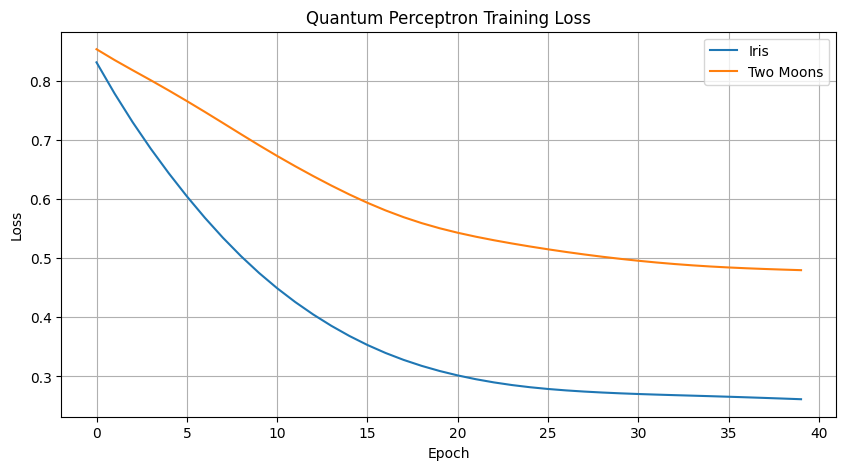

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(iris_losses, label="Iris")
plt.plot(moons_losses, label="Two Moons")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Quantum Perceptron Training Loss")

plt.legend()
plt.grid()
plt.show()

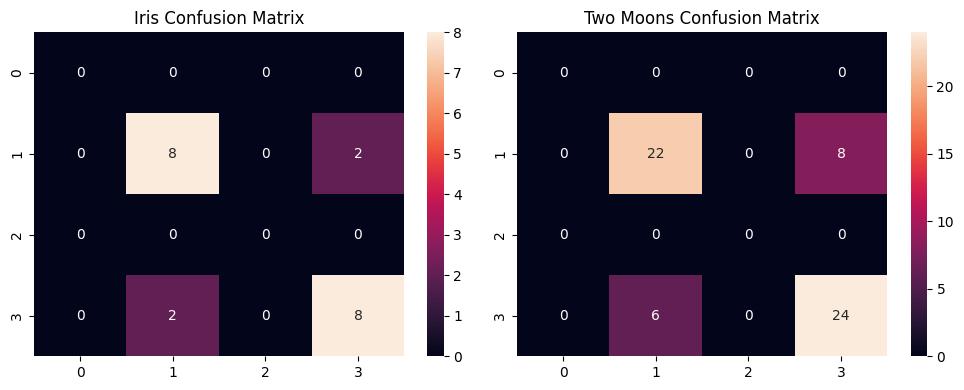

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(
    iris_results[2],
    annot=True,
    fmt="d",
    ax=axes[0]
)

axes[0].set_title("Iris Confusion Matrix")

sns.heatmap(
    moons_results[2],
    annot=True,
    fmt="d",
    ax=axes[1]
)

axes[1].set_title("Two Moons Confusion Matrix")

plt.tight_layout()
plt.show()

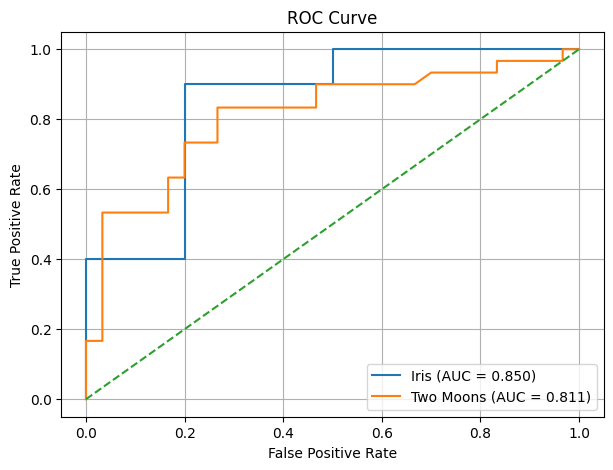

In [21]:
plt.figure(figsize=(7, 5))

for name, y_test, results in [
    ("Iris", y_test_i, iris_results),
    ("Two Moons", y_test_m, moons_results)
]:

    fpr, tpr, _ = roc_curve(y_test, results[0])

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {results[3]:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

In [22]:
circuit_info = qml.specs(quantum_circuit)(
    np.array([0.5, 0.8]),
    iris_weights
)

circuit_depth = circuit_info["resources"].depth

print("QUANTUM COMPUTATIONAL COST")
print("--------------------------")

print("Number of Qubits:", n_qubits)
print("Circuit Depth:", circuit_depth)
print("Shots during evaluation:", 1000)

print("\nIRIS")
print("Training Time:", iris_time)
print("Inference Time:", iris_results[4])
print("Training Sample Evaluations:", len(X_train_i) * 40)
print("Inference Circuit Evaluations:", len(X_test_i))

print("\nTWO MOONS")
print("Training Time:", moons_time)
print("Inference Time:", moons_results[4])
print("Training Sample Evaluations:", len(X_train_m) * 40)
print("Inference Circuit Evaluations:", len(X_test_m))

QUANTUM COMPUTATIONAL COST
--------------------------
Number of Qubits: 2
Circuit Depth: 2
Shots during evaluation: 1000

IRIS
Training Time: 79.43003273010254
Inference Time: 0.23067641258239746
Training Sample Evaluations: 3200
Inference Circuit Evaluations: 20

TWO MOONS
Training Time: 239.79586362838745
Inference Time: 1.2195236682891846
Training Sample Evaluations: 9600
Inference Circuit Evaluations: 60


In [23]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro-F1",
        "AUROC",
        "Qubits",
        "Circuit Depth",
        "Shots",
        "Training Time",
        "Inference Time"
    ],

    "Iris": [
        accuracy_score(y_test_i, iris_results[1]),
        balanced_accuracy_score(y_test_i, iris_results[1]),
        f1_score(y_test_i, iris_results[1], average="macro"),
        iris_results[3],
        n_qubits,
        circuit_depth,
        1000,
        iris_time,
        iris_results[4]
    ],

    "Two Moons": [
        accuracy_score(y_test_m, moons_results[1]),
        balanced_accuracy_score(y_test_m, moons_results[1]),
        f1_score(y_test_m, moons_results[1], average="macro"),
        moons_results[3],
        n_qubits,
        circuit_depth,
        1000,
        moons_time,
        moons_results[4]
    ]
})

print(comparison.to_string(index=False))

comparison.to_csv("quantum_perceptron_results.csv", index=False)

           Metric        Iris   Two Moons
         Accuracy    0.800000    0.766667
Balanced Accuracy    0.800000    0.766667
         Macro-F1    0.800000    0.766407
            AUROC    0.850000    0.810556
           Qubits    2.000000    2.000000
    Circuit Depth    2.000000    2.000000
            Shots 1000.000000 1000.000000
    Training Time   79.430033  239.795864
   Inference Time    0.230676    1.219524


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
